# Larsen 2024 PdAg — independent source-law and selected-data audit

This notebook is a separate, self-contained audit of the historical selected-curve reproduction. It leaves `larsen_2024_benchmark.ipynb`, its parameters, and the digitized curve file unchanged.

**This is not a refit and not a full-data reproduction.** It holds the Figure 6.6 parameter vectors fixed and compares two interpretations of the second rate denominator: the no-superscript first adsorption factor printed in Eq. 6.11, and the squared factor used in the historical benchmark and Appendix F's *standard* LHHW code. The final extended fit implementation is not available in the source.

The model has C₂H₂, C₂H₄, C₂H₆, H₂, and He only. Larsen did not study CO. Pressure and rate units, the MFC flow reference state, the actual reaction temperature, and final catalyst-specific fit masks remain unresolved. Numerical scenarios below are therefore controlled comparisons under explicitly stated inferred conventions.

## Source anchors and fixed conventions

- Main text Eq. 6.11: first adsorption denominator factor has **no printed exponent** (PDF p. 43 / printed p. 37).
- Appendix F standard code: squared adsorption denominator and linear inhibition factor (PDF p. 81 / printed p. 75); it is not the final eight-parameter model.
- Historical benchmark: squared adsorption denominator with fitted inhibition exponent.
- Figure 6.6: eight fixed fitted parameters and reported overall RMSE values (PDF p. 44 / printed p. 38).
- Appendix F `flow_ml_min` conversion uses `P*Q/(R*T)` with `T=373 K`, `P=100000 Pa` (PDF pp. 81–82 / printed pp. 75–76). No MFC standard-flow definition is given.

**Candidate numerical basis, not source-certified:** pressure in Pa, rates in mol kg-cat⁻¹ s⁻¹, `P_reactor=100000 Pa`, `T_flow_ref=373.15 K`, `P_flow_ref=100000 Pa`, tube diameter 0.005 m, and support density 2650 kg m⁻³. Figure 6.6 does not define all parameter units. Methods text says 80 °C, while abstract/Table 6.1 and Appendix F code say 100 °C. No temperature dependence is applied to the published rate coefficients here.

In [1]:
from pathlib import Path
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import solve_ivp
from IPython.display import display

HERE = Path.cwd()
if (HERE / "data").is_dir() and (HERE / "data/larsen_2024_selected_curves.csv").exists():
    BENCHMARK_DIR = HERE
    REPO_ROOT = HERE.parents[1]
elif (HERE / "notebooks/benchmarks/data").is_dir():
    REPO_ROOT = HERE
    BENCHMARK_DIR = HERE / "notebooks/benchmarks"
else:
    raise FileNotFoundError("Run from the repository root or notebooks/benchmarks")
DATA_DIR = BENCHMARK_DIR / "data"
DERIVED_DIR = REPO_ROOT / "research/evidence/derived"

curves = pd.read_csv(DATA_DIR / "larsen_2024_selected_curves.csv")
parameters = pd.read_csv(DATA_DIR / "larsen_2024_parameters.csv").set_index("catalyst")
crosswalk = pd.read_csv(DERIVED_DIR / "larsen_2024_selected_experiment_id_crosswalk.csv")
appendix_rows = pd.read_csv(DERIVED_DIR / "larsen_2024_appendix_F_selected_processed_responses.csv")

print({"python": sys.version.split()[0], "platform": platform.platform(),
       "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
       "matplotlib": plt.matplotlib.__version__})
print("Selected rows by response origin:")
display(curves.groupby(["catalyst", "response_origin"]).size().rename("n_rows").to_frame())
assert len(curves) == 45
assert curves.groupby("catalyst").size().to_dict() == {"Pd0Ag": 15, "Pd2Ag": 15, "Pd3Ag": 15}
assert np.allclose(curves[["feed_C2H2_vol_pct", "feed_C2H4_vol_pct", "feed_H2_vol_pct", "feed_He_vol_pct"]].sum(axis=1), 100.0)
assert "CO" not in curves.columns
assert set(parameters.index) == {"Pd0Ag", "Pd2Ag", "Pd3Ag"}

{'python': '3.12.14', 'platform': 'Linux-6.18.55-x86_64-with-glibc2.41', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Selected rows by response origin:


,,n_rows
catalyst,response_origin,
Pd0Ag,exact_appendix_F_table,15
Pd2Ag,visual_digitization,15
Pd3Ag,visual_digitization,15


## Steady-state packed-bed model

For the no-CO model, the species order is `[C₂H₂, C₂H₄, C₂H₆, H₂, He]`. The stoichiometric columns correspond to `C₂H₂ + H₂ → C₂H₄` and `C₂H₄ + H₂ → C₂H₆`. The reactor is integrated over catalyst-bed length using the source-inferred support-density geometry and fixed Figure 6.6 vectors. We do not add fitted values or change a parameter between denominator variants.

In [2]:
R = 8.314462618  # J mol^-1 K^-1
P_REACTOR_PA = 100_000.0
T_FLOW_REF_K = 373.15
P_FLOW_REF_PA = 100_000.0
TUBE_DIAMETER_M = 0.005
SUPPORT_DENSITY_KG_M3 = 2650.0
AREA_M2 = np.pi * TUBE_DIAMETER_M**2 / 4.0
CATALYST_ORDER = ["Pd0Ag", "Pd2Ag", "Pd3Ag"]
STOICH = np.array([[-1.0, 0.0], [1.0, -1.0], [0.0, 1.0], [-1.0, -1.0], [0.0, 0.0]])
ELEMENTS = np.array([[2.0, 2.0, 2.0, 0.0, 0.0],
                     [2.0, 4.0, 6.0, 2.0, 0.0],
                     [0.0, 0.0, 0.0, 0.0, 1.0]])  # C atoms, H atoms, inert He


def rates_from_flows(flows_mol_s, par, r2_adsorption_power, pressure_input_scale=1.0):
    flows = np.maximum(np.asarray(flows_mol_s, dtype=float), 0.0)
    total_flow = max(float(flows.sum()), 1e-30)
    p_a, p_e, _, p_h, _ = flows / total_flow * P_REACTOR_PA * pressure_input_scale
    ads_1 = 1.0 + par.K_C2H2*p_a + par.K_C2H4*p_e + par.K_H2*p_h
    r1_raw = par.k1 * par.K_C2H2*p_a * par.K_H2*p_h / ads_1**2
    r1 = r1_raw / (1.0 + r1_raw / par.r1_max)
    ads_2 = 1.0 + par.K_C2H2*p_a + par.K_C2H4*p_e
    inhibition = 1.0 + par.K_inh*p_a
    r2 = (par.k2 * par.K_C2H4*p_e * par.K_H2*p_h /
          (ads_2**r2_adsorption_power * inhibition**par.n_inh))
    return np.array([r1, r2])


def simulate_one(row, r2_adsorption_power=1, flow_reference_T_K=T_FLOW_REF_K,
                 flow_reference_P_Pa=P_FLOW_REF_PA, method="BDF", rtol=1e-8, atol=1e-15,
                 parameter_table=parameters, pressure_input_scale=1.0):
    par = parameter_table.loc[row.catalyst]
    q_m3_s = row.flow_ml_min * 1e-6 / 60.0
    total_molar_flow = flow_reference_P_Pa * q_m3_s / (R * flow_reference_T_K)
    inlet = total_molar_flow * np.array([
        row.feed_C2H2_vol_pct, row.feed_C2H4_vol_pct, 0.0,
        row.feed_H2_vol_pct, row.feed_He_vol_pct,
    ]) / 100.0
    mass_kg = row.catalyst_mass_mg * 1e-6
    bed_length_m = mass_kg / (SUPPORT_DENSITY_KG_M3 * AREA_M2)
    mass_per_length = SUPPORT_DENSITY_KG_M3 * AREA_M2

    def rhs(_z, flows):
        return mass_per_length * STOICH @ rates_from_flows(flows, par, r2_adsorption_power, pressure_input_scale)

    result = solve_ivp(rhs, (0.0, bed_length_m), inlet, method=method,
                       rtol=rtol, atol=atol)
    if not result.success:
        raise RuntimeError(f"{row.catalyst} {row.figure} integration failed: {result.message}")
    outlet = result.y[:, -1]
    conversion = 100.0 * (1.0 - outlet[0] / inlet[0])
    selectivity = 100.0 * (outlet[1] - inlet[1]) / (inlet[0] - outlet[0])
    atom_residual = ELEMENTS @ (outlet - inlet)
    return {
        "model_conversion_pct": conversion,
        "model_selectivity_pct": selectivity,
        "bed_length_mm": bed_length_m * 1e3,
        "minimum_state_mol_s": float(result.y.min()),
        "minimum_outlet_mol_s": float(outlet.min()),
        "max_abs_element_residual_mol_atoms_s": float(np.abs(atom_residual).max()),
        "solver_success": result.success,
    }

assert np.allclose(ELEMENTS @ STOICH, 0.0, atol=1e-14)
assert STOICH.shape == (5, 2)
print("Elemental invariants per reaction (C, H, He):")
display(pd.DataFrame(ELEMENTS @ STOICH, index=["C", "H", "He"], columns=["r1", "r2"]))

Elemental invariants per reaction (C, H, He):


,r1,r2
C,0.0,0.0
H,0.0,0.0
He,0.0,0.0


In [3]:
# A consistent Pa-to-kPa change must rescale every reciprocal-pressure adsorption constant.
# This checks dimensional implementation only; it cannot identify the units Larsen used.
scaled_parameters = parameters.copy()
for column in ["K_C2H2", "K_H2", "K_C2H4", "K_inh"]:
    scaled_parameters[column] *= 1000.0
unit_scale_deltas = []
for row in curves.itertuples(index=False):
    pa_result = simulate_one(row, r2_adsorption_power=2)
    kpa_result = simulate_one(row, r2_adsorption_power=2,
                              parameter_table=scaled_parameters, pressure_input_scale=1e-3)
    unit_scale_deltas.append(max(abs(pa_result["model_conversion_pct"]-kpa_result["model_conversion_pct"]),
                                 abs(pa_result["model_selectivity_pct"]-kpa_result["model_selectivity_pct"])))
max_unit_scale_delta = max(unit_scale_deltas)
print("Max response change under consistent Pa-to-kPa parameter conversion (pp):", max_unit_scale_delta)
assert max_unit_scale_delta < 1e-4

Max response change under consistent Pa-to-kPa parameter conversion (pp): 7.467804152838653e-10


## Controlled equation comparison (no refit)

The paired experiment score below follows Eqs. 4.14–4.15: calculate one root-mean-square of the conversion and selectivity errors for each selected row, then average those row scores. This selected subset is not the 41/42/41 final fitting population.

In [4]:
def paired_rmse_per_row(observed_conversion, predicted_conversion,
                        observed_selectivity, predicted_selectivity):
    dx = np.asarray(predicted_conversion) - np.asarray(observed_conversion)
    ds = np.asarray(predicted_selectivity) - np.asarray(observed_selectivity)
    return np.sqrt((dx**2 + ds**2) / 2.0)

# Synthetic hand-check for the printed equation's paired metric.
assert np.isclose(paired_rmse_per_row([0], [3], [0], [4])[0], np.sqrt(12.5))

prediction_rows = []
for variant, power in [("printed Eq. 6.11 (implicit first power)", 1),
                       ("historical/Appendix F squared variant", 2)]:
    for idx, row in curves.iterrows():
        prediction_rows.append({"row_index": idx, "r2_variant": variant,
                                **simulate_one(row, r2_adsorption_power=power)})
predictions = curves.reset_index(names="row_index").merge(pd.DataFrame(prediction_rows), on="row_index")
predictions["paired_rmse_pct_points"] = paired_rmse_per_row(
    predictions.conversion_pct, predictions.model_conversion_pct,
    predictions.selectivity_pct, predictions.model_selectivity_pct)

selected_metrics = (predictions.groupby(["catalyst", "r2_variant"], sort=False)
                    .agg(n_selected=("row_index", "size"),
                         selected_paired_rmse_pct_points=("paired_rmse_pct_points", "mean"),
                         selected_conversion_rmse_pct_points=("model_conversion_pct",
                            lambda s: np.sqrt(np.mean((s.to_numpy()-predictions.loc[s.index, "conversion_pct"].to_numpy())**2))),
                         selected_selectivity_rmse_pct_points=("model_selectivity_pct",
                            lambda s: np.sqrt(np.mean((s.to_numpy()-predictions.loc[s.index, "selectivity_pct"].to_numpy())**2))))
                    .reset_index())
display(selected_metrics.round(6))

# Regression against the previous notebook's executed selected-curve scores; this checks
# unchanged parameters, data and the squared-law implementation, not source correctness.
expected_historical = {"Pd0Ag": 5.268026, "Pd2Ag": 5.470034, "Pd3Ag": 21.081482}
squared = selected_metrics[selected_metrics.r2_variant.str.startswith("historical")].set_index("catalyst")
regression_deltas = {cat: float(squared.loc[cat, "selected_paired_rmse_pct_points"] - value)
                     for cat, value in expected_historical.items()}
assert max(abs(v) for v in regression_deltas.values()) < 0.02, regression_deltas
print("Delta from historical squared-law selected metrics (percentage points):", regression_deltas)
assert predictions[["model_conversion_pct", "model_selectivity_pct"]].to_numpy().shape == (90, 2)
assert np.isfinite(predictions[["model_conversion_pct", "model_selectivity_pct"]]).all().all()

,catalyst,r2_variant,n_selected,selected_paired_rmse_pct_points,selected_conversion_rmse_pct_points,selected_selectivity_rmse_pct_points
0,Pd0Ag,printed Eq. 6.11 (implicit first power),15,13.445027,6.713071,20.030736
1,Pd0Ag,historical/Appendix F squared variant,15,5.268026,6.713415,4.806342
2,Pd2Ag,printed Eq. 6.11 (implicit first power),15,15.488563,5.120973,25.567704
3,Pd2Ag,historical/Appendix F squared variant,15,5.470034,5.156931,7.324179
4,Pd3Ag,printed Eq. 6.11 (implicit first power),15,21.288119,0.805703,41.661385
5,Pd3Ag,historical/Appendix F squared variant,15,21.081482,0.805704,41.481733


Delta from historical squared-law selected metrics (percentage points): {'Pd0Ag': 1.7274146113521738e-07, 'Pd2Ag': 4.251641216868052e-07, 'Pd3Ag': -1.1269621325027401e-07}


## Appendix F processed-row cross-check vs Figure 6.1–6.4 digitizations

Appendix F shows processed `conv`/`selec` outputs for 42 Pd₂Ag rows and only a head/tail preview for Pd₃Ag. These are author-processed responses (the thesis code comments identify them as experiment responses), not raw GC peak areas or a recovered workbook. We condition-match the selected curves to the visible table rows and report differences; a matching operating condition alone does not prove the chart marker and table row are identical. The old selected-curve CSV remains unchanged.

In [5]:
cw = crosswalk.copy()
source_check = curves.reset_index(names="row_index").merge(
    cw[["catalyst", "figure", "figure_x_value", "matched_appendix_F_experiment_id"]],
    left_on=["catalyst", "figure", "independent_value"],
    right_on=["catalyst", "figure", "figure_x_value"], how="left")
source_check = source_check.merge(appendix_rows, left_on=["catalyst", "matched_appendix_F_experiment_id"],
                                  right_on=["catalyst", "experiment_id"], how="left")
source_check["source_response_class"] = np.where(
    source_check.catalyst.eq("Pd0Ag"), "Pd0 selected Appendix F processed row (prior exact transcription)",
    source_check.response_class.fillna("not displayed in Appendix F preview"))
source_check["source_conversion_pct"] = np.where(
    source_check.catalyst.eq("Pd0Ag"), source_check.conversion_pct,
    source_check.appendix_F_processed_conversion_pct)
source_check["source_selectivity_pct"] = np.where(
    source_check.catalyst.eq("Pd0Ag"), source_check.selectivity_pct,
    source_check.appendix_F_processed_selectivity_pct)
source_check["source_response_available"] = source_check.source_conversion_pct.notna()
source_check["digitization_minus_table_conversion_pp"] = (
    source_check.conversion_pct-source_check.source_conversion_pct)
source_check["digitization_minus_table_selectivity_pp"] = (
    source_check.selectivity_pct-source_check.source_selectivity_pct)
source_check["conversion_within_digitization_uncertainty"] = (
    source_check.digitization_minus_table_conversion_pp.abs() <= source_check.digitization_uncertainty_pp)
source_check["selectivity_within_digitization_uncertainty"] = (
    source_check.digitization_minus_table_selectivity_pp.abs() <= source_check.digitization_uncertainty_pp)

mapped = source_check[source_check.source_response_available].copy()
concordance = mapped[["catalyst", "figure", "series", "independent_value", "matched_appendix_F_experiment_id",
                      "response_origin", "conversion_pct", "source_conversion_pct",
                      "digitization_minus_table_conversion_pp", "selectivity_pct", "source_selectivity_pct",
                      "digitization_minus_table_selectivity_pp", "digitization_uncertainty_pp",
                      "conversion_within_digitization_uncertainty", "selectivity_within_digitization_uncertainty"]]
print("Selected rows with visible source processed responses:", len(mapped), "of", len(source_check))
display(concordance.round(4))
print("Count of mapped point responses outside the ±2 pp marker reading band:")
display(concordance.groupby("catalyst")[["conversion_within_digitization_uncertainty",
                                             "selectivity_within_digitization_uncertainty"]].apply(lambda x: (~x).sum()))

Selected rows with visible source processed responses: 34 of 45


,catalyst,figure,series,independent_value,matched_appendix_F_experiment_id,response_origin,conversion_pct,source_conversion_pct,digitization_minus_table_conversion_pp,selectivity_pct,source_selectivity_pct,digitization_minus_table_selectivity_pp,digitization_uncertainty_pp,conversion_within_digitization_uncertainty,selectivity_within_digitization_uncertainty
0,Pd0Ag,6.1,flow,120000,EXP1,exact_appendix_F_table,10.4626,10.4626,0.0000,99.7161,99.7161,0.0000,0,True,True
1,Pd0Ag,6.1,flow,90000,EXP2,exact_appendix_F_table,20.9913,20.9913,0.0000,98.8585,98.8585,0.0000,0,True,True
2,Pd0Ag,6.1,flow,60000,EXP3,exact_appendix_F_table,41.1478,41.1478,0.0000,98.7598,98.7598,0.0000,0,True,True
3,Pd0Ag,6.1,flow,30000,EXP4,exact_appendix_F_table,89.9764,89.9764,0.0000,94.9607,94.9607,0.0000,0,True,True
4,Pd2Ag,6.1,flow,160000,EXP1,visual_digitization,58.0000,58.0189,-0.0189,95.0000,95.6002,-0.6002,2,True,True
5,Pd2Ag,6.1,flow,120000,EXP2,visual_digitization,87.0000,86.4178,0.5822,94.0000,94.2433,-0.2433,2,True,True
6,Pd2Ag,6.1,flow,80000,EXP3,visual_digitization,100.0000,99.2764,0.7236,85.0000,84.8868,0.1132,2,True,True
7,Pd2Ag,6.1,flow,40000,EXP4,visual_digitization,99.0000,99.3495,-0.3495,56.0000,55.8465,0.1535,2,True,True
8,Pd3Ag,6.1,flow,120000,EXP1,visual_digitization,99.0000,99.7486,-0.7486,69.0000,68.8914,0.1086,2,True,True
9,Pd3Ag,6.1,flow,90000,EXP2,visual_digitization,99.0000,99.7148,-0.7148,56.0000,56.1657,-0.1657,2,True,True


Count of mapped point responses outside the ±2 pp marker reading band:


,conversion_within_digitization_uncertainty,selectivity_within_digitization_uncertainty
catalyst,,
Pd0Ag,0,0
Pd2Ag,2,1
Pd3Ag,0,1


In [6]:
# Compare both fixed-parameter models with the source-processed mapped subset.
source_prediction_rows = []
for variant, power in [("printed Eq. 6.11 (implicit first power)", 1),
                       ("historical/Appendix F squared variant", 2)]:
    for row in mapped.itertuples(index=False):
        sim = simulate_one(row, r2_adsorption_power=power)
        source_prediction_rows.append({"row_index": row.row_index, "r2_variant": variant, **sim})
source_predictions = mapped.merge(pd.DataFrame(source_prediction_rows), on="row_index")
source_predictions["paired_rmse_pct_points"] = paired_rmse_per_row(
    source_predictions.source_conversion_pct, source_predictions.model_conversion_pct,
    source_predictions.source_selectivity_pct, source_predictions.model_selectivity_pct)
source_metrics = (source_predictions.groupby(["catalyst", "r2_variant"], sort=False)
                  .agg(n_visible_source_rows=("row_index", "size"),
                       mapped_source_subset_paired_rmse_pct_points=("paired_rmse_pct_points", "mean"))
                  .reset_index())
display(source_metrics.round(5))
print("These are selected source-row checks, not the final Figure 6.6 fit-set RMSEs.")
assert source_predictions.groupby(["r2_variant", "catalyst"]).size().to_dict() == {
    ("printed Eq. 6.11 (implicit first power)", "Pd0Ag"): 15,
    ("printed Eq. 6.11 (implicit first power)", "Pd2Ag"): 15,
    ("printed Eq. 6.11 (implicit first power)", "Pd3Ag"): 4,
    ("historical/Appendix F squared variant", "Pd0Ag"): 15,
    ("historical/Appendix F squared variant", "Pd2Ag"): 15,
    ("historical/Appendix F squared variant", "Pd3Ag"): 4,
}
assert all((r.catalyst == "Pd0Ag") or ("raw GC unavailable" in str(r.response_class)) for r in source_predictions.itertuples())

,catalyst,r2_variant,n_visible_source_rows,mapped_source_subset_paired_rmse_pct_points
0,Pd0Ag,printed Eq. 6.11 (implicit first power),15,13.44503
1,Pd0Ag,historical/Appendix F squared variant,15,5.26803
2,Pd2Ag,printed Eq. 6.11 (implicit first power),15,16.38333
3,Pd2Ag,historical/Appendix F squared variant,15,6.16635
4,Pd3Ag,printed Eq. 6.11 (implicit first power),4,9.70027
5,Pd3Ag,historical/Appendix F squared variant,4,9.58146


These are selected source-row checks, not the final Figure 6.6 fit-set RMSEs.


## Numerical verification and solver sensitivity

The tolerances here test integration stability for this numerical scenario; they do not validate inferred units or the experimental response definitions. Atom balance is checked both algebraically and from inlet/outlet integrations. Solver comparisons use unchanged inputs and coefficients.

In [7]:
baseline = predictions[predictions.r2_variant.str.startswith("printed")]
solver_checks = []
max_solver_delta = 0.0
max_tight_delta = 0.0
max_element_residual = 0.0
min_state = np.inf
for variant, power in [("printed Eq. 6.11", 1), ("squared alternative", 2)]:
    for row in curves.itertuples(index=False):
        base = simulate_one(row, r2_adsorption_power=power, method="BDF", rtol=1e-8, atol=1e-15)
        radau = simulate_one(row, r2_adsorption_power=power, method="Radau", rtol=1e-8, atol=1e-15)
        tight = simulate_one(row, r2_adsorption_power=power, method="BDF", rtol=1e-10, atol=1e-17)
        solver_delta = max(abs(base["model_conversion_pct"]-radau["model_conversion_pct"]),
                           abs(base["model_selectivity_pct"]-radau["model_selectivity_pct"]))
        tight_delta = max(abs(base["model_conversion_pct"]-tight["model_conversion_pct"]),
                          abs(base["model_selectivity_pct"]-tight["model_selectivity_pct"]))
        max_solver_delta = max(max_solver_delta, solver_delta)
        max_tight_delta = max(max_tight_delta, tight_delta)
        max_element_residual = max(max_element_residual, base["max_abs_element_residual_mol_atoms_s"])
        min_state = min(min_state, base["minimum_state_mol_s"])
        solver_checks.append({"variant": variant, "catalyst": row.catalyst, "figure": row.figure,
                              "solver_max_abs_delta_pp": solver_delta,
                              "tight_tolerance_max_abs_delta_pp": tight_delta,
                              "min_state_mol_s": base["minimum_state_mol_s"],
                              "max_abs_element_residual_mol_atoms_s": base["max_abs_element_residual_mol_atoms_s"]})
solver_checks = pd.DataFrame(solver_checks)
print({"max BDF-vs-Radau response delta (pp)": max_solver_delta,
       "max BDF base-vs-tight response delta (pp)": max_tight_delta,
       "most negative integrated flow state (mol/s)": min_state,
       "max absolute elemental-flow residual (mol atoms/s)": max_element_residual})
assert max_solver_delta < 1e-4
assert max_tight_delta < 1e-4
assert min_state > -1e-10
assert max_element_residual < 1e-10
assert solver_checks.solver_max_abs_delta_pp.max() < 1e-4

rmse_check = predictions.groupby(["catalyst", "r2_variant"]).apply(
    lambda f: np.sqrt(((f.model_conversion_pct-f.conversion_pct)**2 +
                       (f.model_selectivity_pct-f.selectivity_pct)**2)/2).mean(),
    include_groups=False)
metric_check = selected_metrics.set_index(["catalyst", "r2_variant"]).selected_paired_rmse_pct_points
assert np.allclose(rmse_check.sort_index(), metric_check.sort_index(), atol=1e-12)
print("RMSE implementation agrees with a direct Eq. 4.14–4.15 expression to 1e-12 pp.")

{'max BDF-vs-Radau response delta (pp)': np.float64(1.730516351017286e-05), 'max BDF base-vs-tight response delta (pp)': np.float64(1.6914683349966708e-05), 'most negative integrated flow state (mol/s)': -6.621506681483621e-17, 'max absolute elemental-flow residual (mol atoms/s)': 2.8936763060575035e-19}
RMSE implementation agrees with a direct Eq. 4.14–4.15 expression to 1e-12 pp.


## Flow-reference and temperature scenarios

The Appendix F code computes molar flow from the listed `mL/min` using its 100 °C code temperature and 100 kPa total pressure, but does not name an MFC standard state. The following are sensitivity cases: actual-volume assumptions at 80 and 100 °C; and example standard-volume conventions at 0, 20, and 25 °C with 1 atm reference pressure. The reactor pressure remains 100 kPa in every case. This isolates the flow-to-molar-flow ambiguity; no Arrhenius correction or temperature-specific fitted parameter is made.

In [8]:
flow_cases = [
    ("source code: actual at 100C, 100kPa", 373.15, 100_000.0),
    ("methods narrative: actual at 80C, 100kPa", 353.15, 100_000.0),
    ("example standard: 0C, 1atm", 273.15, 101_325.0),
    ("example standard: 20C, 1atm", 293.15, 101_325.0),
    ("example standard: 25C, 1atm", 298.15, 101_325.0),
]
flow_results = []
for case, temp_ref, p_ref in flow_cases:
    for variant, power in [("printed Eq. 6.11 (implicit first power)", 1),
                           ("historical/Appendix F squared variant", 2)]:
        for row in curves.itertuples(index=False):
            sim = simulate_one(row, r2_adsorption_power=power,
                               flow_reference_T_K=temp_ref, flow_reference_P_Pa=p_ref)
            flow_results.append({"flow_case": case, "flow_reference_T_K": temp_ref,
                                 "flow_reference_P_Pa": p_ref, "r2_variant": variant,
                                 "catalyst": row.catalyst,
                                 "conversion_pct": row.conversion_pct,
                                 "selectivity_pct": row.selectivity_pct,
                                 **sim})
flow_predictions = pd.DataFrame(flow_results)
flow_predictions["paired_rmse_pct_points"] = paired_rmse_per_row(
    flow_predictions.conversion_pct, flow_predictions.model_conversion_pct,
    flow_predictions.selectivity_pct, flow_predictions.model_selectivity_pct)
flow_metrics = (flow_predictions.groupby(["flow_case", "r2_variant", "catalyst"], sort=False)
                .agg(n_selected=("paired_rmse_pct_points", "size"),
                     selected_paired_rmse_pct_points=("paired_rmse_pct_points", "mean"),
                     mean_conversion_pct=("model_conversion_pct", "mean"),
                     mean_selectivity_pct=("model_selectivity_pct", "mean"))
                .reset_index())
display(flow_metrics.round(4))
assert len(flow_predictions) == 5 * 2 * 45
assert np.isfinite(flow_metrics.select_dtypes(include=[np.number])).all().all()

,flow_case,r2_variant,catalyst,n_selected,selected_paired_rmse_pct_points,mean_conversion_pct,mean_selectivity_pct
0,"source code: actual at 100C, 100kPa",printed Eq. 6.11 (implicit first power),Pd0Ag,15,13.4450,62.2186,75.6265
1,"source code: actual at 100C, 100kPa",printed Eq. 6.11 (implicit first power),Pd2Ag,15,15.4886,96.8205,39.5116
2,"source code: actual at 100C, 100kPa",printed Eq. 6.11 (implicit first power),Pd3Ag,15,21.2881,99.9996,-49.6225
3,"source code: actual at 100C, 100kPa",historical/Appendix F squared variant,Pd0Ag,15,5.2680,62.2598,89.7876
4,"source code: actual at 100C, 100kPa",historical/Appendix F squared variant,Pd2Ag,15,5.4700,96.8351,58.3937
5,"source code: actual at 100C, 100kPa",historical/Appendix F squared variant,Pd3Ag,15,21.0815,99.9996,-48.9526
6,"methods narrative: actual at 80C, 100kPa",printed Eq. 6.11 (implicit first power),Pd0Ag,15,13.0529,59.8047,76.2249
7,"methods narrative: actual at 80C, 100kPa",printed Eq. 6.11 (implicit first power),Pd2Ag,15,12.9414,96.0511,43.0815
8,"methods narrative: actual at 80C, 100kPa",printed Eq. 6.11 (implicit first power),Pd3Ag,15,20.4017,99.9991,-41.7213
9,"methods narrative: actual at 80C, 100kPa",historical/Appendix F squared variant,Pd0Ag,15,5.1809,59.8440,90.2007


## Visual comparison and persisted derived outputs

The parity/overlay views are a compact visual check of both equations against the selected response subset. Points labelled as digitized retain their ±2 pp reading uncertainty; the source-table cross-check above is separately labelled. Published Figure 6.6 RMSE values are context only and are not calculated from these subsets.

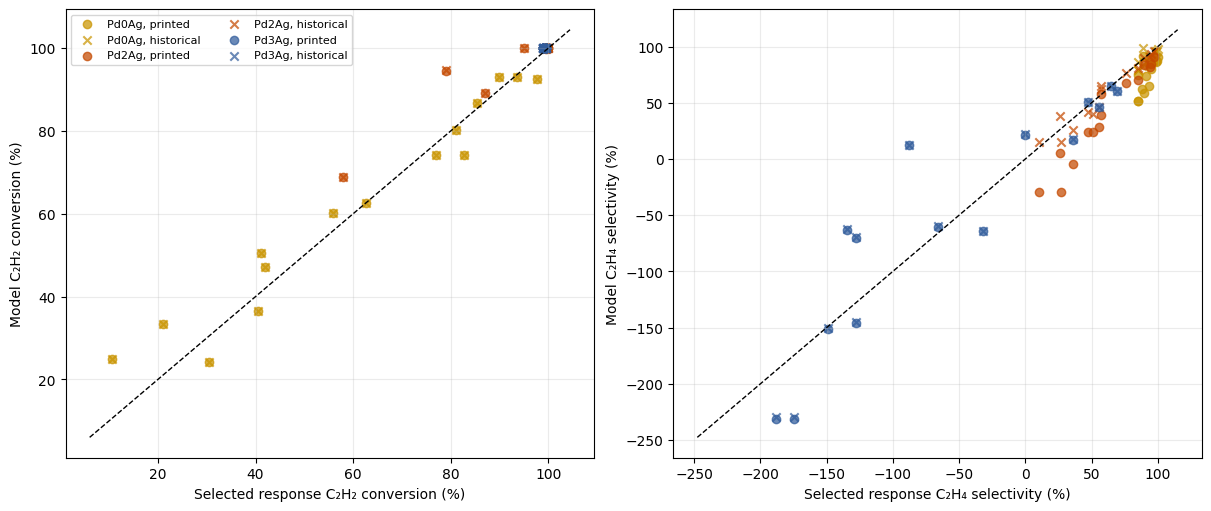

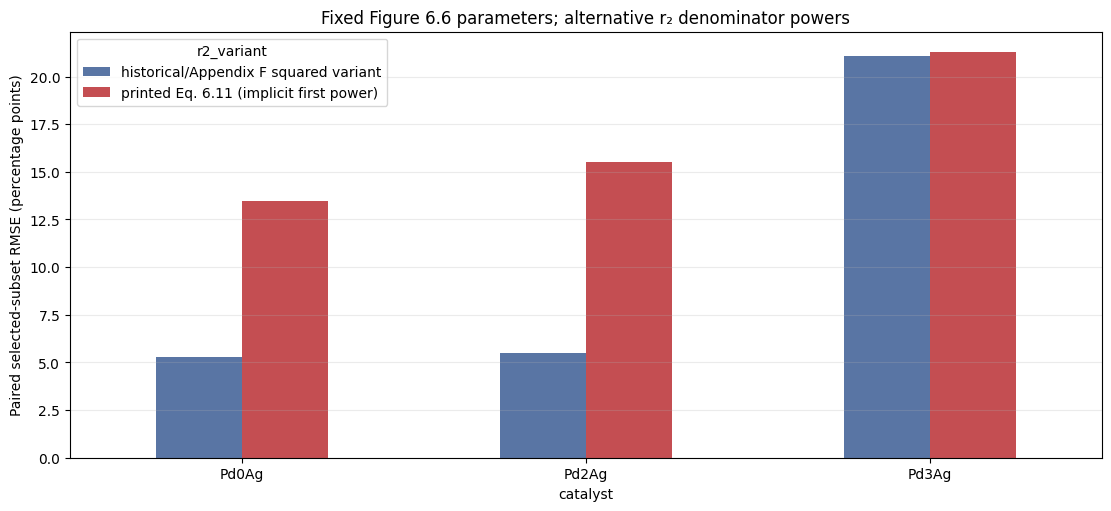

Wrote source-law predictions, flow scenarios, solver/balance checks, mapped-source subset metrics, and response cross-check to research/evidence/derived/.


In [9]:
colors = {"Pd0Ag": "#c99400", "Pd2Ag": "#c44900", "Pd3Ag": "#315c9b"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, observed, model, label in [
    (axes[0], "conversion_pct", "model_conversion_pct", "C₂H₂ conversion (%)"),
    (axes[1], "selectivity_pct", "model_selectivity_pct", "C₂H₄ selectivity (%)")]:
    for cat in CATALYST_ORDER:
        for variant, marker in [("printed", "o"), ("historical", "x")]:
            part = predictions[(predictions.catalyst == cat) & predictions.r2_variant.str.startswith(variant)]
            ax.scatter(part[observed], part[model], color=colors[cat], marker=marker,
                       alpha=0.72, label=f"{cat}, {variant}")
    lo = min(ax.get_xlim()[0], ax.get_ylim()[0]); hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([lo, hi], [lo, hi], "k--", linewidth=1)
    ax.set_xlabel(f"Selected response {label}"); ax.set_ylabel(f"Model {label}")
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8, ncol=2)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
plot_metrics = selected_metrics.pivot(index="catalyst", columns="r2_variant",
                                     values="selected_paired_rmse_pct_points").loc[CATALYST_ORDER]
plot_metrics.plot(kind="bar", ax=ax, color=["#5975a4", "#c44e52"])
ax.set_ylabel("Paired selected-subset RMSE (percentage points)")
ax.set_title("Fixed Figure 6.6 parameters; alternative r₂ denominator powers")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.show()

# Stable audit artifacts. They distinguish selected plot data from source-processed rows.
selected_predictions = predictions.drop(columns=["row_index"]).merge(
    crosswalk[["catalyst", "figure", "figure_x_value", "matched_appendix_F_experiment_id",
               "appendix_F_processed_conversion_pct", "appendix_F_processed_selectivity_pct",
               "response_provenance", "source_display_status"]],
    left_on=["catalyst", "figure", "independent_value"],
    right_on=["catalyst", "figure", "figure_x_value"], how="left")
selected_predictions.to_csv(DERIVED_DIR / "larsen_2024_source_law_selected_predictions.csv", index=False)
flow_metrics.to_csv(DERIVED_DIR / "larsen_2024_flow_reference_sensitivity.csv", index=False)
solver_checks.to_csv(DERIVED_DIR / "larsen_2024_solver_and_balance_checks.csv", index=False)
source_metrics.to_csv(DERIVED_DIR / "larsen_2024_mapped_processed_subset_metrics.csv", index=False)
concordance.to_csv(DERIVED_DIR / "larsen_2024_plot_vs_appendix_response_crosscheck.csv", index=False)
print("Wrote source-law predictions, flow scenarios, solver/balance checks, mapped-source subset metrics, and response cross-check to research/evidence/derived/.")

## Interpretation limits

1. The first-power Eq. 6.11 comparison is source-faithful to the printed *equation*, but the final extended-fit implementation and final catalyst-specific row masks are not shown. Appendix F's displayed fit function is a different six-variable standard model.
2. The squared-denominator case reproduces the historical selected-subset scores under its inferred units. It does not prove that Larsen used that formula for Figure 6.6.
3. Pd₂Ag's selected operating conditions have matching Appendix F processed rows; Pd₃Ag has matching displayed head rows for Figure 6.1 only. Source-table values are still processed responses rather than raw GC data. Any plot/table discrepancies are recorded rather than silently resolved.
4. The 80 °C vs 100 °C text/code conflict, MFC flow reference state, coefficient units, PDF official-version identity, selectivity/byproduct coverage, and Pd₃Ag 36-row final-fit mask remain open.
5. Published Figure 6.6 overall RMSE claims (5.0962, 5.4320, 7.1353 pp; N=41/42/41) are not recalculated here. The available independent data subset is 15 Pd₀Ag rows, 15 mapped Pd₂Ag processed rows, and 4 visible Pd₃Ag processed rows, with separate 15-row-per-catalyst chart-digitalization results.